First 5 records:
   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1                 91  
1                                 2                 65  
2                                 2                 45  
3                                 2                 36  
4                                 5                 66  

Dataset Shape: (10000, 6)

Missing Values:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours         

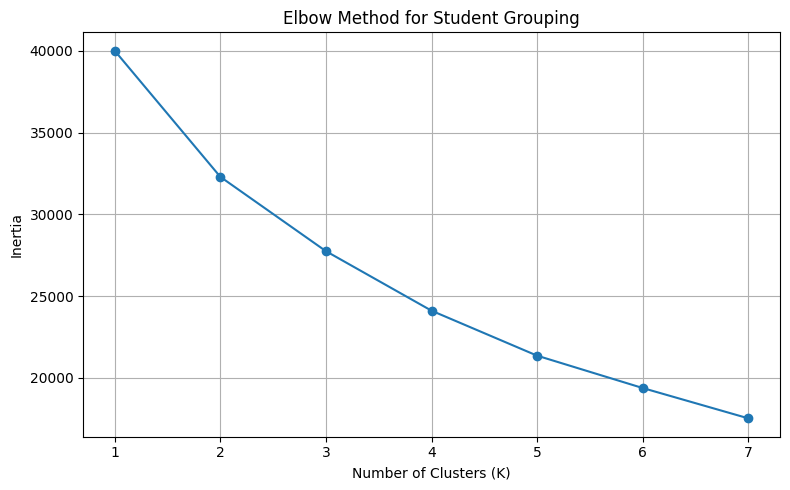

Enter the selected number of clusters K: 5


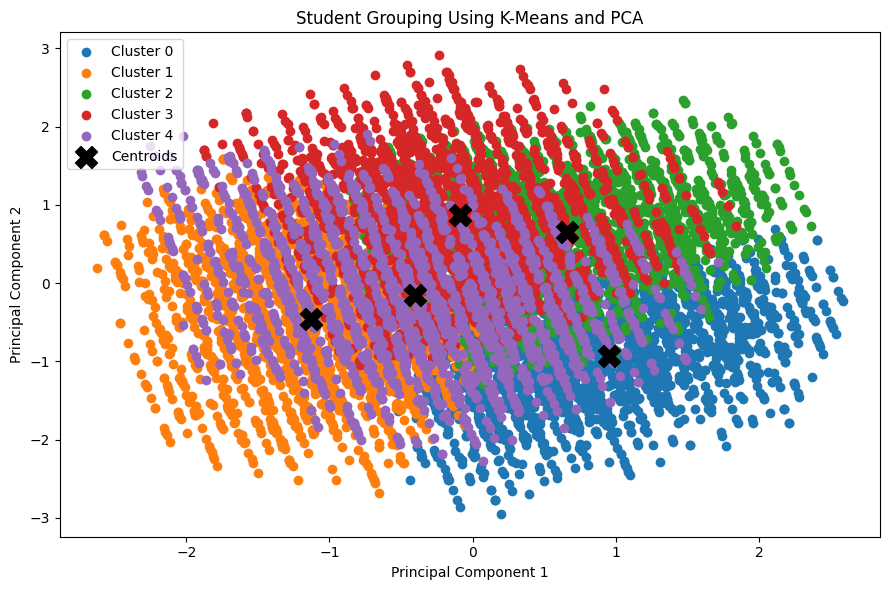


Student Cluster Profiles:
         StudentCount  AvgHoursStudied  AvgPreviousScores  AvgSleepHours  \
Cluster                                                                    
0                1996             6.84              53.05           5.76   
1                1955             3.07              71.60           4.92   
2                1977             7.17              86.86           6.38   
3                2021             2.62              71.29           7.52   
4                2051             5.27              64.75           7.99   

         AvgPracticePapers  AvgPerformanceIndex  
Cluster                                          
0                     6.03                43.74  
1                     2.64                50.87  
2                     5.60                79.28  
3                     6.93                51.25  
4                     1.73                51.27  

Student Data with Cluster Labels:
   Hours Studied  Previous Scores Extracurricular Activ

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 1. Load the dataset
df = pd.read_csv("/content/Student_Performance - Student_Performance.csv")

print("First 5 records:")
print(df.head())

# 2. Inspect the dataset
print("\nDataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nSummary Statistics:")
print(df.describe())

# 3. Select at least three relevant numerical features
features = [
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced"
]

X = df[features].copy()

# Handle missing numerical values
X = X.fillna(X.mean())

# 4. Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Elbow Method
inertias = []

for k in range(1, 8):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 8), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Student Grouping")
plt.xticks(range(1, 8))
plt.grid(True)
plt.tight_layout()
plt.show()

# 6. Select K based on the elbow plot
k = int(input("Enter the selected number of clusters K: "))

if k < 2 or k > 7:
    raise ValueError("K must be between 2 and 7.")

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# 7. Reduce the scaled features to 2 dimensions using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot student clusters
plt.figure(figsize=(9, 6))

for cluster in sorted(df["Cluster"].unique()):
    cluster_data = X_pca[df["Cluster"].values == cluster]

    plt.scatter(
        cluster_data[:, 0],  # x coordinates
        cluster_data[:, 1],  # y coordinates
        label=f"Cluster {cluster}"
    )

# Plot centroids in the same PCA space
centroids_pca = pca.transform(kmeans.cluster_centers_)  #centroid into the same two PCA dimensions

plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Student Grouping Using K-Means and PCA")
plt.legend()
plt.tight_layout()
plt.show()

# 8. Interpret the cluster profiles
df["Performance Index"] = pd.to_numeric(
    df["Performance Index"], errors="coerce"
)

summary = df.groupby("Cluster").agg(
    StudentCount=("Cluster", "size"),
    AvgHoursStudied=("Hours Studied", "mean"),
    AvgPreviousScores=("Previous Scores", "mean"),
    AvgSleepHours=("Sleep Hours", "mean"),
    AvgPracticePapers=("Sample Question Papers Practiced", "mean"),
    AvgPerformanceIndex=("Performance Index", "mean")
).round(2)

print("\nStudent Cluster Profiles:")
print(summary)

# 9. Display student records with cluster labels
print("\nStudent Data with Cluster Labels:")
print(df.head(10))

# 10. Save the clustered dataset
df.to_csv("Student_Performance_Clustered.csv", index=False)
print("\nClustered dataset saved successfully.")
